# Mustafa Abbas Abokhadher
# 2240002889
# 7MA2

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [11]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
try:
    from google.colab import files   # only needed on Colab
except ImportError:
    pass

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [12]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [15]:
ile_path = '/content/drive/MyDrive/Lab11/Lab_11_QnA_Dataset.csv'
df = pd.read_csv(file_path)

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
print(df.head())

Number of questions: 168
Number of answer groups: 12
               question  answer_id                answer
0      Do you get hurt?          0  I don't have a body.
1  Do you have fingers?          0  I don't have a body.
2   Do you ever breathe          0  I don't have a body.
3     Do you masticate?          0  I don't have a body.
4     Can you throw up?          0  I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [16]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [17]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [18]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

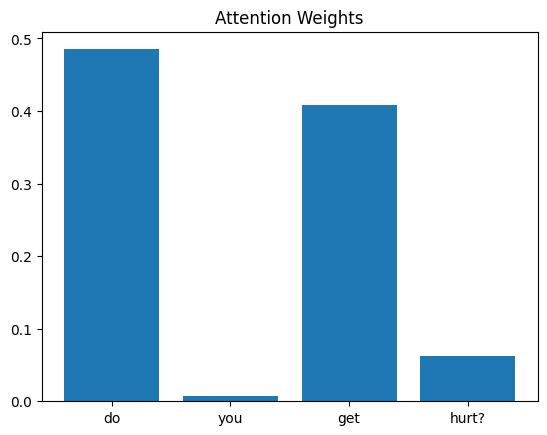

In [19]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question : Who created you?
  Highest-attention word: "who" (0.592)   | weight on padding: 0.250
  Predicted answer 3: People created me.   (true: People created me.)

Question : Do you have a name?
  Highest-attention word: "name?" (0.920)   | weight on padding: 0.004
  Predicted answer 2: I'm better at answering questions.   (true: I don't have a name.)

Question : What do you eat?
  Highest-attention word: "eat?" (0.528)   | weight on padding: 0.024
  Predicted answer 10: Not at all.   (true: I don't need to eat.)



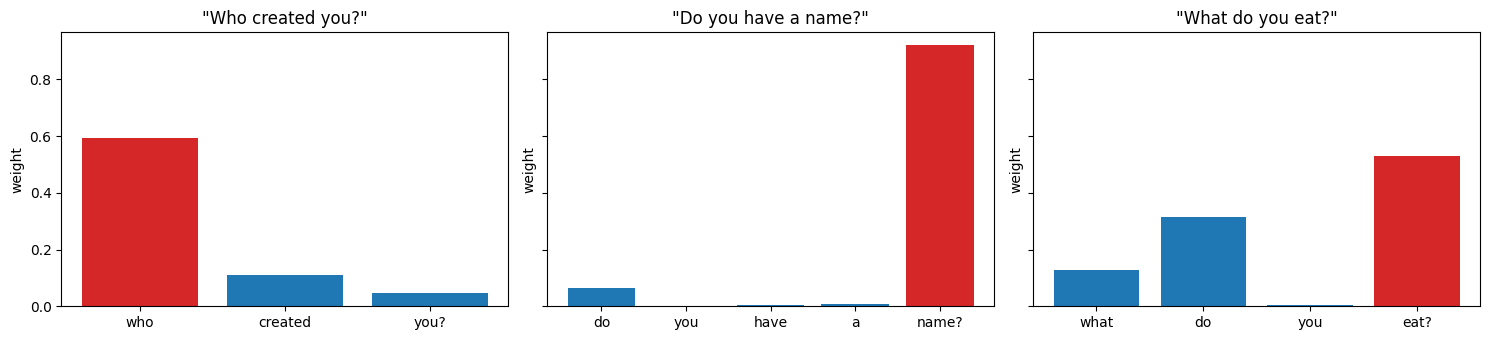

In [20]:
# Task 1: attention weights for three different questions
answers = df.drop_duplicates("answer_id").set_index("answer_id")["answer"]

def plot_attention(question, ax):
    q = question.lower()
    idx = df.index[df["question"] == q][0]
    words = q.split()
    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])
    w = weights[0, :len(words)].tolist()
    pad_w = weights[0, len(words):].sum().item()          # attention that went to padding
    top = words[max(range(len(w)), key=lambda i: w[i])]
    pred_id = prediction.argmax(1).item()

    bars = ax.bar(words, w, color=["tab:red" if x == top else "tab:blue" for x in words])
    ax.set_title(f'"{question}"')
    ax.set_ylabel("weight")
    print(f'Question : {question}')
    print(f'  Highest-attention word: "{top}" ({max(w):.3f})   | weight on padding: {pad_w:.3f}')
    print(f'  Predicted answer {pred_id}: {answers[pred_id]}   (true: {answers[y[idx].item()]})\n')

selected = ["Who created you?", "Do you have a name?", "What do you eat?"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for question, ax in zip(selected, axes):
    plot_attention(question, ax)
plt.tight_layout()
plt.show()

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question : Who built you?
  Highest-attention word: "built" (0.585)   | weight on padding: 0.117
  Predicted answer 3: People created me.   (true: People created me.)

Question : Which company made you?
  Highest-attention word: "which" (0.526)   | weight on padding: 0.057
  Predicted answer 3: People created me.   (true: People created me.)



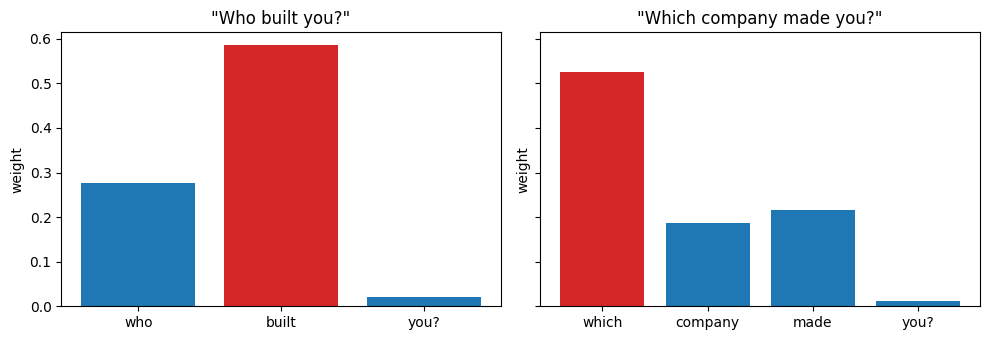

In [21]:
# Task 2: two questions with a similar meaning but different wording (both ask who made the bot)
pair = ["Who built you?", "Which company made you?"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for question, ax in zip(pair, axes):
    plot_attention(question, ax)
plt.tight_layout()
plt.show()

**Answer – Task 2**

Both questions belong to the same answer group ("People created me.") and the model answered both correctly, but it focused on **different words**: *built* (≈0.59) in the first question and *which* (≈0.53, followed by *made* and *company*) in the second.

**What this suggests:**
- Attention does not look for the "same meaning" or the same word. It is a set of weights learned from the training data, and the model uses whichever words were useful for separating the answers (here *who*, *built*, *which*, *made*, *company* are all linked with "People created me.").
- The model does not truly understand that *built* and *made* are synonyms; it only learned that several different cues point to the same answer.
- Attention weights show where the model looked, but they are only a partial explanation of why it chose an answer.

### Bonus – note about Step 5
The training loop in Step 5 does not call `optimizer.zero_grad()`, so the gradients pile up from one epoch to the next. The model above reaches only ≈38% training accuracy. The cell below trains the same model **with** `zero_grad()` and compares the attention on the same questions.

In [22]:
torch.manual_seed(42)
model_fixed = RNN()
opt_fixed = torch.optim.Adam(model_fixed.parameters(), lr=0.01)

for epoch in range(50):
    opt_fixed.zero_grad()                                   # <- the missing line
    loss = nn.functional.cross_entropy(model_fixed(X)[0], y)
    loss.backward()
    opt_fixed.step()

with torch.no_grad():
    acc_old = (model(X)[0].argmax(1) == y).float().mean().item()
    acc_new = (model_fixed(X)[0].argmax(1) == y).float().mean().item()
print(f"Training accuracy  without zero_grad: {acc_old:.2f}  |  with zero_grad: {acc_new:.2f}\n")

for q in ["Who created you?", "Do you have a name?", "What do you eat?", "Who built you?", "Which company made you?"]:
    idx = df.index[df["question"] == q.lower()][0]
    words = q.lower().split()
    with torch.no_grad():
        pred, w = model_fixed(X[idx:idx + 1])
    w = w[0, :len(words)].tolist()
    top = words[max(range(len(w)), key=lambda i: w[i])]
    print(f'{q:25} top word: {top:10} ({max(w):.2f})  predicted: {answers[pred.argmax(1).item()]}')

Training accuracy  without zero_grad: 0.38  |  with zero_grad: 0.99

Who created you?          top word: who        (0.43)  predicted: People created me.
Do you have a name?       top word: name?      (0.52)  predicted: I don't have a body.
What do you eat?          top word: eat?       (0.53)  predicted: I don't need to eat.
Who built you?            top word: who        (0.61)  predicted: People created me.
Which company made you?   top word: company    (0.41)  predicted: People created me.
